In [1]:
import json
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_dir = Path("../data/raw/train/train_images")
json_path = Path("../data/raw/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")

# 1. Parse JSON
with open(json_path, "r") as f:
    coco = json.load(f)

image_dict = {img["id"]: img["file_name"] for img in coco["images"]}
image_ids = list(image_dict.keys())

# ponytail: setdefault groups annotations cleanly
ann_dict = {}
for ann in coco["annotations"]:
    ann_dict.setdefault(ann["image_id"], []).append(ann)

# 2. Split MUST come before Dataset creation
counts = [len(ann_dict.get(i, [])) for i in image_ids]
bins = np.digitize(counts, bins=[3, 7, 12, 18]) 
train_ids, val_ids = train_test_split(image_ids, test_size=0.2, stratify=bins, random_state=42)

print(f"Dataset indexed: {len(train_ids)} Train | {len(val_ids)} Val")

/home/virendra2605/Documents/inter-iit-cvps/task-a-solar-fragments/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset indexed: 923 Train | 231 Val


In [14]:
# 1. Verification Metric
def calculate_iou(logits, targets, threshold=0.5, eps=1e-6):
    preds = (torch.sigmoid(logits) > threshold).float()
    intersection = (preds * targets).sum(dim=(2, 3))
    union = (preds + targets).sum(dim=(2, 3)) - intersection
    return ((intersection + eps) / (union + eps)).mean().item()

# 2. Training Dataset (512x512 Biased Crops + D4 Augmentation)
class FilamentDataset(Dataset):
    def __init__(self, image_ids, img_dir, img_dict, ann_dict, size=(512, 512), augment=False):
        self.image_ids = image_ids
        self.img_dir = img_dir
        self.img_dict = img_dict
        self.ann_dict = ann_dict
        self.size = size
        self.augment = augment
        
    def __len__(self): 
        return len(self.image_ids)
        
    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_path = str(self.img_dir / self.img_dict[img_id])
        
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = np.zeros_like(image, dtype=np.uint8)
        
        centers = []
        for ann in self.ann_dict.get(img_id, []):
            for poly in ann.get("segmentation", []):
                poly_pts = np.round(np.array(poly, dtype=np.float32).reshape(-1, 2)).astype(np.int32)
                cv2.fillPoly(mask, [poly_pts], 1)
                centers.append(poly_pts.mean(axis=0))
                
        h, w = image.shape
        th, tw = self.size
        
        # Biased cropping
        if len(centers) > 0 and torch.rand(1).item() > 0.5:
            cx, cy = centers[torch.randint(len(centers), (1,)).item()]
            i = np.clip(int(cy) - th // 2, 0, h - th)
            j = np.clip(int(cx) - tw // 2, 0, w - tw)
        else:
            i = torch.randint(0, h - th + 1, size=(1,)).item()
            j = torch.randint(0, w - tw + 1, size=(1,)).item()
            
        image = image[i:i+th, j:j+tw]
        mask = mask[i:i+th, j:j+tw]
        
        image = torch.from_numpy(image).float().unsqueeze(0) / 255.0
        mask = torch.from_numpy(mask).float().unsqueeze(0)
        
        # ponytail: Lazy D4 augmentation applied only to training crops.
        if self.augment:
            if torch.rand(1).item() > 0.5:
                image = torch.flip(image, dims=[2])
                mask = torch.flip(mask, dims=[2])
            if torch.rand(1).item() > 0.5:
                image = torch.flip(image, dims=[1])
                mask = torch.flip(mask, dims=[1])
                
        return image, mask

# 3. Full-Disk Dataset (Pure, unaugmented for strict 2048x2048 evaluation)
class FullDiskDataset(Dataset):
    def __init__(self, image_ids, img_dir, img_dict, ann_dict):
        self.image_ids = image_ids
        self.img_dir = img_dir
        self.img_dict = img_dict
        self.ann_dict = ann_dict
        
    def __len__(self): 
        return len(self.image_ids)
        
    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_path = str(self.img_dir / self.img_dict[img_id])
        
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = np.zeros_like(image, dtype=np.uint8)
        
        for ann in self.ann_dict.get(img_id, []):
            for poly in ann.get("segmentation", []):
                poly_pts = np.round(np.array(poly, dtype=np.float32).reshape(-1, 2)).astype(np.int32)
                cv2.fillPoly(mask, [poly_pts], 1)
                
        image = torch.from_numpy(image).float().unsqueeze(0) / 255.0
        mask = torch.from_numpy(mask).float().unsqueeze(0)
        return image, mask

# 4. Clean post-processing filter
def remove_small_objects(binary_mask, min_size=64):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask.astype(np.uint8), connectivity=8)
    clean_mask = np.zeros_like(binary_mask)
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_size:
            clean_mask[labels == i] = 1
    return clean_mask

# 5. Instantiate Loaders
train_dataset = FilamentDataset(train_ids, train_dir, image_dict, ann_dict, size=(512, 512), augment=True)
val_dataset = FilamentDataset(val_ids, train_dir, image_dict, ann_dict, size=(512, 512), augment=False)
full_val_dataset = FullDiskDataset(val_ids, train_dir, image_dict, ann_dict)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

print("Scaffolding compiled. Loaders and datasets are ready.")

Scaffolding compiled. Loaders and datasets are ready.


In [ ]:
class ResNetUNet(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet34(weights=None)
        
        self.firstconv = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.firstbn = resnet.bn1
        self.firstrelu = resnet.relu
        self.firstmaxpool = resnet.maxpool
        
        self.encoder1 = resnet.layer1
        self.encoder2 = resnet.layer2
        self.encoder3 = resnet.layer3
        self.encoder4 = resnet.layer4
        
        def dec_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1), nn.InstanceNorm2d(out_c), nn.LeakyReLU(0.01, inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1), nn.InstanceNorm2d(out_c), nn.LeakyReLU(0.01, inplace=True)
            )
            
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = dec_block(512, 256) 
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = dec_block(256, 128) 
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = dec_block(128, 64)  
        self.up1 = nn.ConvTranspose2d(64, 64, 2, stride=2)
        self.dec1 = dec_block(128, 64)  
        
        self.final_up = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.final_dec = dec_block(32, 16)
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e0 = self.firstrelu(self.firstbn(self.firstconv(x)))
        e1 = self.encoder1(self.firstmaxpool(e0))
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        b = self.encoder4(e3)
        
        d4 = self.dec4(torch.cat([self.up4(b), e3], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e2], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e0], 1))
        return self.out(self.final_dec(self.final_up(d1)))

# Instantiate and load saved peak weights
model = ResNetUNet().to(device)

#This is the path to the model weights file. Make sure the file exists in the working directory before running the code. saved along with the notebooks here
model_path = "./models/best_resnet_unet_final.pt"

if Path(model_path).exists():
    model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"Loaded weights from {model_path}")
else:
    raise FileNotFoundError(f"Checkpoint {model_path} not found in working directory.")

model.eval()

Loaded weights from best_resnet_unet_final.pt


ResNetUNet(
  (firstconv): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (firstbn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (firstrelu): ReLU(inplace=True)
  (firstmaxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (encoder1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias

In [5]:
print("Evaluating full validation set (2048x2048)...")

val_iou, val_precision, val_recall = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="Full-Disk Eval")
    for img_tensor, mask_tensor in pbar:
        img_gpu = img_tensor.unsqueeze(0).to(device)
        mask_np = mask_tensor.squeeze().numpy()
        
        logits = model(img_gpu)
        preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()
        preds_clean = remove_small_objects(preds, min_size=64)
        
        intersection = np.logical_and(preds_clean, mask_np).sum()
        union = np.logical_or(preds_clean, mask_np).sum()
        tp = intersection
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        val_iou += intersection / (union + 1e-6)
        val_precision += tp / (tp + fp + 1e-6)
        val_recall += tp / (tp + fn + 1e-6)

n_val = len(full_val_dataset)
print(f"\nFinal Verified Metrics ({n_val} images):")
print(f"Mean IoU:       {val_iou / n_val:.4f}")
print(f"Mean Precision: {val_precision / n_val:.4f}")
print(f"Mean Recall:    {val_recall / n_val:.4f}")

Evaluating full validation set (2048x2048)...


Full-Disk Eval: 100%|██████████| 231/231 [01:10<00:00,  3.27it/s]


Final Verified Metrics (231 images):
Mean IoU:       0.4700
Mean Precision: 0.6846
Mean Recall:    0.6229


In [17]:
# ponytail: Test-Time Augmentation (TTA). 
# Trades 3x inference time for free recall and boundary smoothing without new dependencies.

print("Evaluating full validation set (2048x2048) with TTA...")

model.eval()
val_iou, val_precision, val_recall = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="Full-Disk TTA Eval")
    for img_tensor, mask_tensor in pbar:
        img_gpu = img_tensor.unsqueeze(0).to(device)
        mask_np = mask_tensor.squeeze().numpy()
        
        # 1. Forward passes across three orientations (dim 2=H, dim 3=W)
        with torch.amp.autocast('cuda'):
            logits_base = model(img_gpu)
            logits_h = torch.flip(model(torch.flip(img_gpu, dims=[3])), dims=[3])
            logits_v = torch.flip(model(torch.flip(img_gpu, dims=[2])), dims=[2])
        
        # 2. Average probabilities before thresholding
        probs = (torch.sigmoid(logits_base) + torch.sigmoid(logits_h) + torch.sigmoid(logits_v)) / 3.0
        preds = (probs > 0.5).squeeze().cpu().numpy()
        
        # 3. Fast area filter to remove speckle noise
        preds_clean = remove_small_objects(preds, min_size=64)
        
        # 4. Metric calculation
        intersection = np.logical_and(preds_clean, mask_np).sum()
        union = np.logical_or(preds_clean, mask_np).sum()
        
        tp = intersection
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        val_iou += intersection / (union + 1e-6)
        val_precision += tp / (tp + fp + 1e-6)
        val_recall += tp / (tp + fn + 1e-6)

n_val = len(full_val_dataset)
print(f"\nFinal TTA Metrics:")
print(f"Mean IoU:       {val_iou / n_val:.4f}")
print(f"Mean Precision: {val_precision / n_val:.4f}")
print(f"Mean Recall:    {val_recall / n_val:.4f}")

Evaluating full validation set (2048x2048) with TTA...


Full-Disk TTA Eval: 100%|██████████| 231/231 [01:57<00:00,  1.96it/s]


Final TTA Metrics:
Mean IoU:       0.4722
Mean Precision: 0.6942
Mean Recall:    0.6175


In [16]:
# 1. Balanced Tversky Loss (trading a tiny bit of precision for a recall bump)
class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.4, beta=0.6, smooth=1.0):
        super().__init__()
        self.alpha = alpha  # Weight for false negatives
        self.beta = beta    # Weight for false positives
        self.smooth = smooth
        
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).view(-1)
        targets = targets.view(-1)
        
        true_pos = (probs * targets).sum()
        false_neg = ((1 - probs) * targets).sum()
        false_pos = (probs * (1 - targets)).sum()
        
        tversky = (true_pos + self.smooth) / (true_pos + self.alpha * false_neg + self.beta * false_pos + self.smooth)
        return 1.0 - tversky

In [12]:
# ponytail: Quick fine-tune with augmentation from your current peak checkpoint.
checkpoint_path = "best_resnet_unet_final.pt"
aug_checkpoint_path = "best_resnet_unet_augmented.pt"

model.load_state_dict(torch.load(checkpoint_path, map_location=device))
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5) # Gentle LR
criterion = TverskyLoss(alpha=0.4, beta=0.6).to(device)

best_val_iou = 0.4722  # Metric to beat
epochs_aug = 5

print("Starting Fine-Tuning with Data Augmentation...")

for epoch in range(epochs_aug):
    model.train()
    train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Aug Epoch {epoch+1}/{epochs_aug}")
    for images, masks in pbar:
        images, masks = images.to(device), masks.to(device)
        
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            logits = model(images)
            loss = criterion(logits, masks)
            
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")
        
    # Validation step on unaugmented val crops
    model.eval()
    val_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            with torch.amp.autocast('cuda'):
                logits = model(images)
            val_iou += calculate_iou(logits, masks)
            
    val_iou_mean = val_iou / len(val_loader)
    print(f"Epoch {epoch+1} | Val Crop IoU: {val_iou_mean:.4f}")
    
    if val_iou_mean > best_val_iou:
        best_val_iou = val_iou_mean
        torch.save(model.state_dict(), aug_checkpoint_path)
        print(f"  -> New best IoU! Saved to {aug_checkpoint_path}")

# Load the best augmented weights
if Path(aug_checkpoint_path).exists():
    model.load_state_dict(torch.load(aug_checkpoint_path, map_location=device))
    print("Augmented peak weights loaded.")

Starting Fine-Tuning with Data Augmentation...


Aug Epoch 1/5: 100%|██████████| 231/231 [00:27<00:00,  8.29it/s, loss=0.2951]


Epoch 1 | Val Crop IoU: 0.5510
  -> New best IoU! Saved to best_resnet_unet_augmented.pt


Aug Epoch 2/5: 100%|██████████| 231/231 [00:27<00:00,  8.33it/s, loss=0.2623]


Epoch 2 | Val Crop IoU: 0.5548
  -> New best IoU! Saved to best_resnet_unet_augmented.pt


...

Epoch 3 | Val Crop IoU: 0.5366


Aug Epoch 4/5: 100%|██████████| 231/231 [00:27<00:00,  8.32it/s, loss=0.4830]


Epoch 4 | Val Crop IoU: 0.5639
  -> New best IoU! Saved to best_resnet_unet_augmented.pt


Aug Epoch 5/5: 100%|██████████| 231/231 [00:27<00:00,  8.34it/s, loss=0.4059]


Epoch 5 | Val Crop IoU: 0.5613
Augmented peak weights loaded.


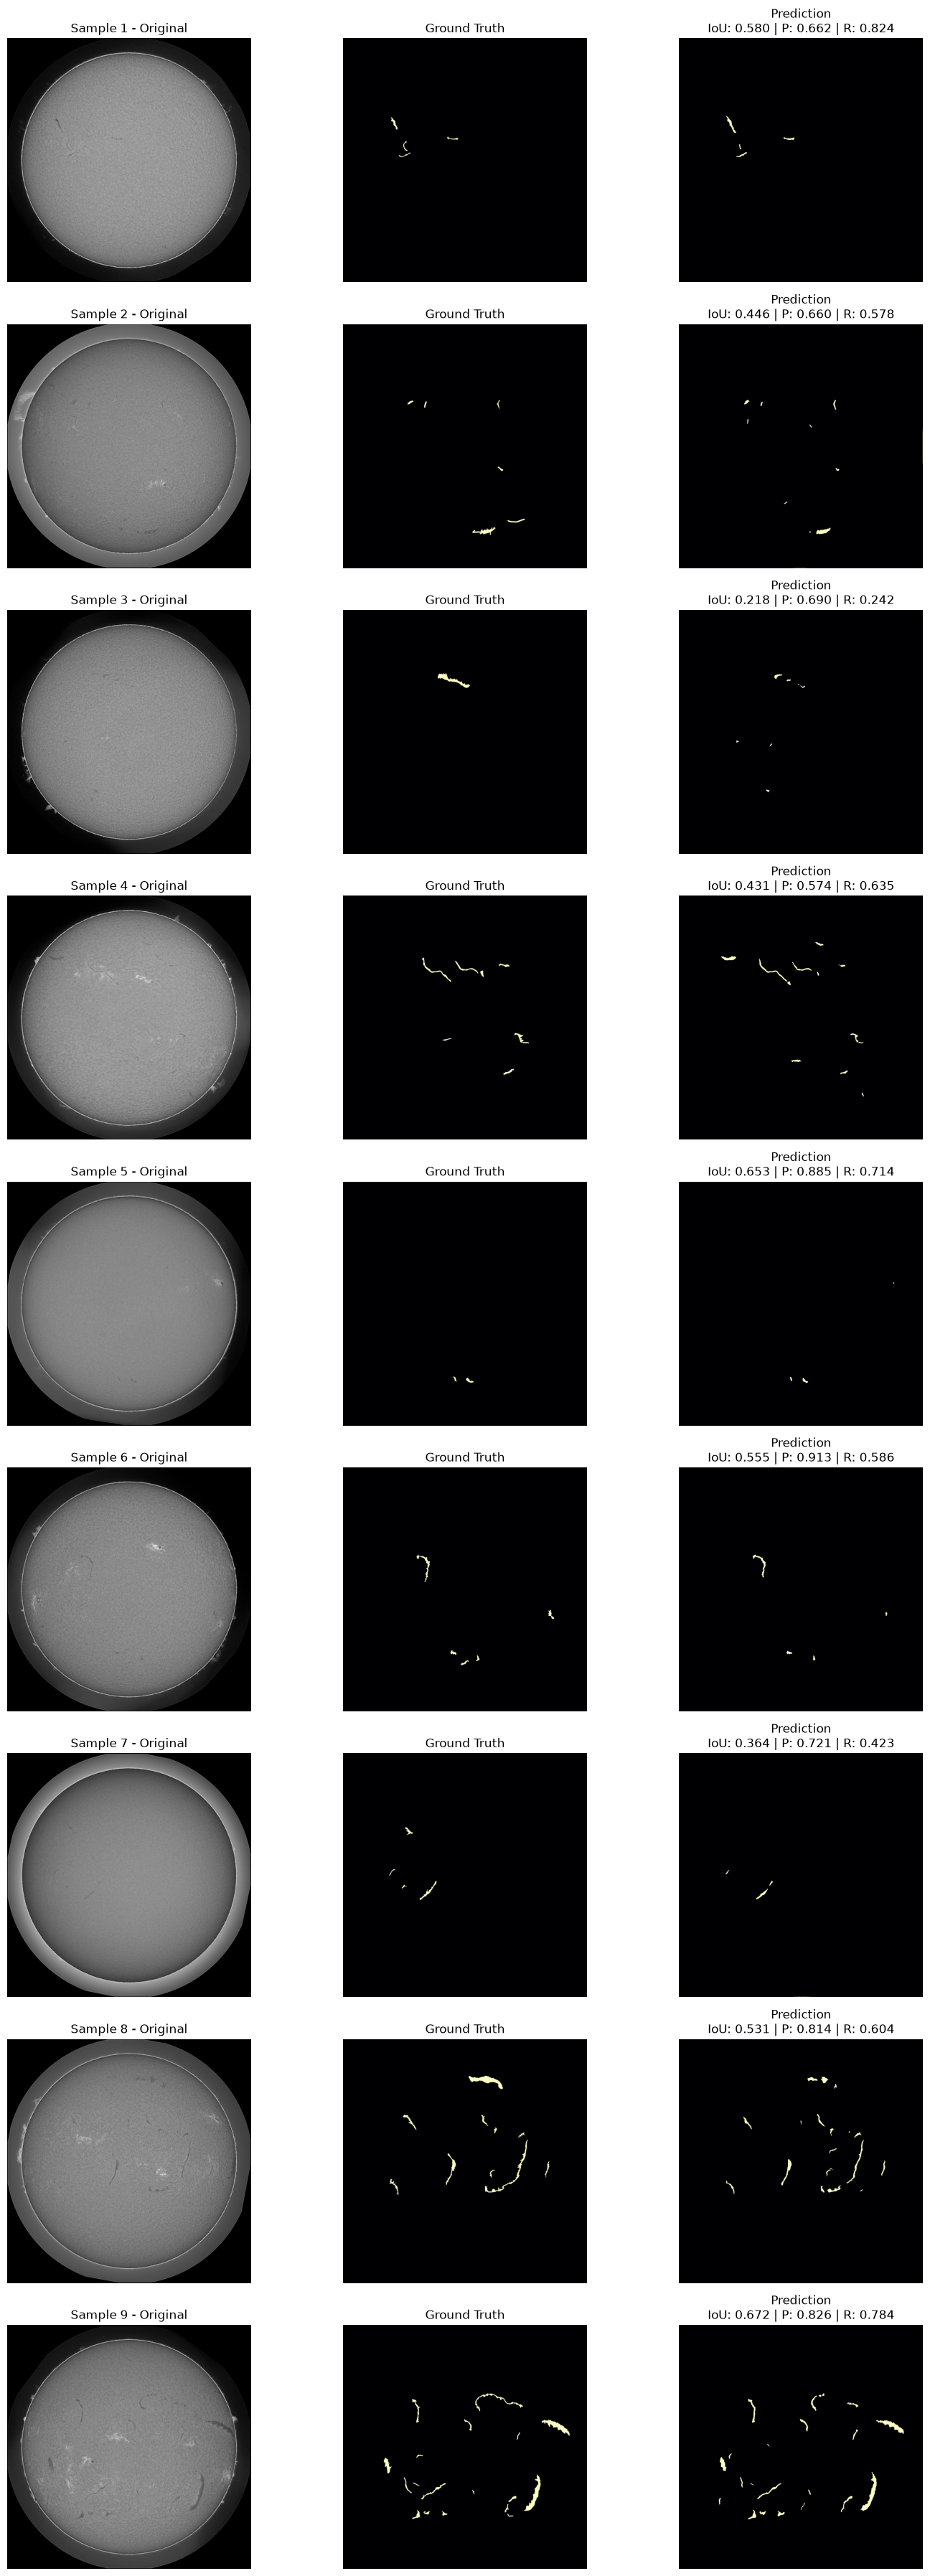

In [19]:
# Grab 9 samples from the full validation dataset and plot in a clean 9x3 grid
num_samples = 9
fig, axes = plt.subplots(num_samples, 3, figsize=(15, 4 * num_samples))

model.eval()
with torch.no_grad():
    for idx in range(num_samples):
        img_tensor, mask_tensor = full_val_dataset[idx]
        
        # Run inference
        img_gpu = img_tensor.unsqueeze(0).to(device)
        logits = model(img_gpu)
        preds = (torch.sigmoid(logits) > 0.5).squeeze().cpu().numpy()
        
        # Apply our fast OpenCV noise filter
        preds_clean = remove_small_objects(preds, min_size=64)
        
        mask_np = mask_tensor.squeeze().numpy()
        img_np = img_tensor.squeeze().numpy()
        
        # Calculate sample-specific metrics
        intersection = np.logical_and(preds_clean, mask_np).sum()
        union = np.logical_or(preds_clean, mask_np).sum()
        tp = intersection
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        iou = intersection / (union + 1e-6)
        precision = tp / (tp + fp + 1e-6)
        recall = tp / (tp + fn + 1e-6)
        
        # Row layout: [Original Image, Ground Truth Mask, Prediction + Metrics]
        ax_img, ax_gt, ax_pred = axes[idx]
        
        ax_img.imshow(img_np, cmap='gray')
        ax_img.set_title(f"Sample {idx+1} - Original")
        ax_img.axis('off')
        
        ax_gt.imshow(mask_np, cmap='magma')
        ax_gt.set_title(f"Ground Truth")
        ax_gt.axis('off')
        
        ax_pred.imshow(preds_clean, cmap='magma')
        ax_pred.set_title(f"Prediction\nIoU: {iou:.3f} | P: {precision:.3f} | R: {recall:.3f}")
        ax_pred.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import torch
import numpy as np
from tqdm.auto import tqdm

print("Compiling all Official Problem Statement Metrics on 2048x2048 validation set...")

# Load your proven local weights
model.load_state_dict(torch.load("best_resnet_unet_final.pt", map_location=device))
model.eval()

# 1. Pixel-level Accumulators
total_tp, total_fp, total_fn, total_union = 0, 0, 0, 0

# 2. Object-level Accumulators
total_gt_objs, total_hits = 0, 0
total_pred_objs, total_valid_preds = 0, 0

# 3. Multi-scale Accumulators
total_iou_s1, total_iou_s2, total_iou_s4 = 0.0, 0.0, 0.0

with torch.no_grad():
    pbar = tqdm(full_val_dataset, desc="PS Metrics Eval")
    for img_tensor, mask_tensor in pbar:
        img_gpu = img_tensor.unsqueeze(0).to(device)
        mask_np = mask_tensor.squeeze().numpy().astype(np.uint8)
        
        # TTA Ensemble for free accuracy
        with torch.amp.autocast('cuda'):
            logits_base = model(img_gpu)
            logits_h = torch.flip(model(torch.flip(img_gpu, dims=[3])), dims=[3])
            logits_v = torch.flip(model(torch.flip(img_gpu, dims=[2])), dims=[2])
        
        probs = (torch.sigmoid(logits_base) + torch.sigmoid(logits_h) + torch.sigmoid(logits_v)) / 3.0
        preds = (probs > 0.5).squeeze().cpu().numpy().astype(np.uint8)
        preds_clean = remove_small_objects(preds, min_size=64)
        
        # --- PIXEL METRICS (IoU, Prec, Rec) ---
        tp = np.logical_and(preds_clean, mask_np).sum()
        fp = (preds_clean > mask_np).sum()
        fn = (mask_np > preds_clean).sum()
        
        total_tp += tp
        total_fp += fp
        total_fn += fn
        
        # --- OBJECT METRICS (Hit, Miss, AP@0) ---
        # ponytail: AP@IoU 0 simply means "if it touches the ground truth at all (IoU > 0), it's a True Positive."
        num_gt, labels_gt = cv2.connectedComponents(mask_np, connectivity=8)
        for i in range(1, num_gt):
            total_gt_objs += 1
            if (preds_clean[labels_gt == i] > 0).any():
                total_hits += 1
                
        num_pred, labels_pred = cv2.connectedComponents(preds_clean, connectivity=8)
        for i in range(1, num_pred):
            total_pred_objs += 1
            if (mask_np[labels_pred == i] > 0).any():
                total_valid_preds += 1
                
        # --- MULTI-SCALE IOU (MIoU) ---
        # ponytail: The PS asks for MIoU to evaluate fine barb structures.
        # We calculate standard IoU at 1x, 0.5x, and 0.25x resolutions and average them.
        def get_scale_iou(p, m, scale):
            if scale != 1.0:
                new_size = (int(p.shape[1] * scale), int(p.shape[0] * scale))
                p = cv2.resize(p, new_size, interpolation=cv2.INTER_NEAREST)
                m = cv2.resize(m, new_size, interpolation=cv2.INTER_NEAREST)
            intersection = np.logical_and(p, m).sum()
            union = np.logical_or(p, m).sum()
            return intersection / (union + 1e-6)
            
        total_iou_s1 += get_scale_iou(preds_clean, mask_np, 1.0)
        total_iou_s2 += get_scale_iou(preds_clean, mask_np, 0.5)
        total_iou_s4 += get_scale_iou(preds_clean, mask_np, 0.25)

# --- FINAL CALCULATIONS ---
n = len(full_val_dataset)

# Global Pixel Metrics
precision = total_tp / (total_tp + total_fp + 1e-6)
recall = total_tp / (total_tp + total_fn + 1e-6)

# Object Metrics
hit_rate = total_hits / (total_gt_objs + 1e-6)
miss_rate = 1.0 - hit_rate 
ap_at_0 = total_valid_preds / (total_pred_objs + 1e-6)

# MIoU
mean_iou = total_iou_s1 / n
miou = (total_iou_s1 + total_iou_s2 + total_iou_s4) / (3 * n)

print("\n=== PROBLEM STATEMENT METRICS ===")
print(f"Mean IoU:         {mean_iou:.4f}")
print(f"Precision:        {precision:.4f} (Global Pixel)")
print(f"Recall:           {recall:.4f} (Global Pixel)")
print(f"Hit Rate:         {hit_rate:.4f} ({total_hits}/{total_gt_objs} GT objects found)")
print(f"Miss Rate:        {miss_rate:.4f}")
print(f"AP@IoU 0:         {ap_at_0:.4f} ({total_valid_preds}/{total_pred_objs} Pred objects valid)")
print(f"Multi-scale IoU:  {miou:.4f} (Averaged across 1x, 0.5x, 0.25x)")

Compiling all Official Problem Statement Metrics on 2048x2048 validation set...


PS Metrics Eval: 100%|██████████| 231/231 [02:10<00:00,  1.77it/s]


=== PROBLEM STATEMENT METRICS ===
Mean IoU:         0.4722
Precision:        0.7215 (Global Pixel)
Recall:           0.6057 (Global Pixel)
Hit Rate:         0.9075 (1482/1633 GT objects found)
Miss Rate:        0.0925
AP@IoU 0:         0.6928 (1838/2653 Pred objects valid)
Multi-scale IoU:  0.4729 (Averaged across 1x, 0.5x, 0.25x)
